In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file = r"D:\Real-Time Acceleration for Medical Image Processing\7986407\CIRS073_RUMC\CIRS073_RUMC\hyper_lesion2\USDATA_20210624113603277.mat"

with h5py.File(file, "r") as f:
    rf = np.array(f["USDATA"])

print("Shape:", rf.shape)
print("Datatype:", rf.dtype)

Shape: (75, 1, 128, 2944)
Datatype: int16


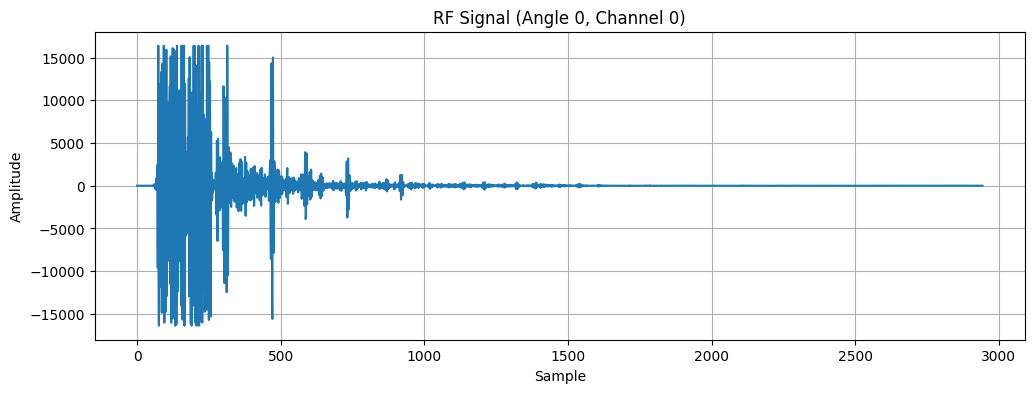

In [2]:
signal = rf[0, 0, 0, :]

plt.figure(figsize=(12,4))
plt.plot(signal)
plt.title("RF Signal (Angle 0, Channel 0)")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

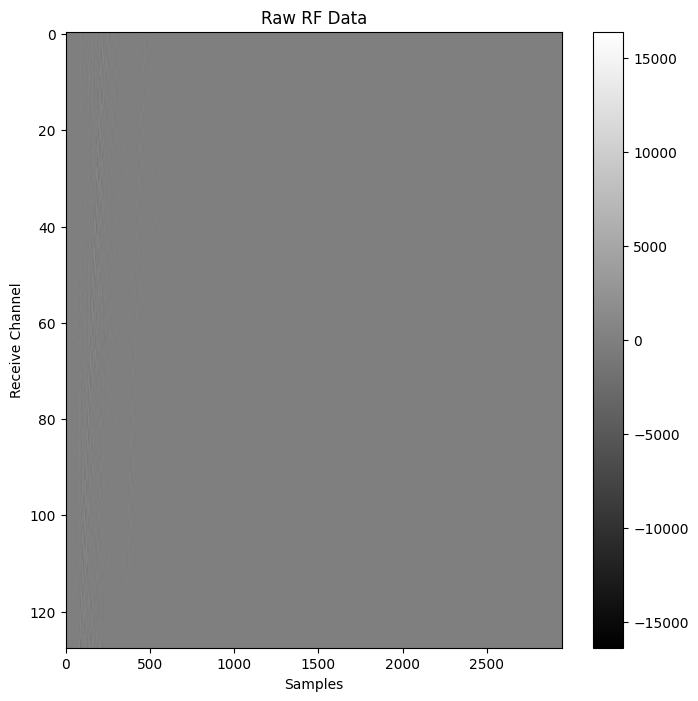

In [3]:
frame = rf[0, 0, :, :]      # shape (128,2944)

plt.figure(figsize=(8,8))
plt.imshow(frame,
           cmap="gray",
           aspect="auto")

plt.xlabel("Samples")
plt.ylabel("Receive Channel")
plt.title("Raw RF Data")
plt.colorbar()
plt.show()

In [4]:
print("Shape:", frame.shape)
print("Min:", frame.min())
print("Max:", frame.max())
print("Mean:", frame.mean())
print("Std:", frame.std())

Shape: (128, 2944)
Min: -16384
Max: 16384
Mean: 0.34792958135190216
Std: 2277.7627751910136


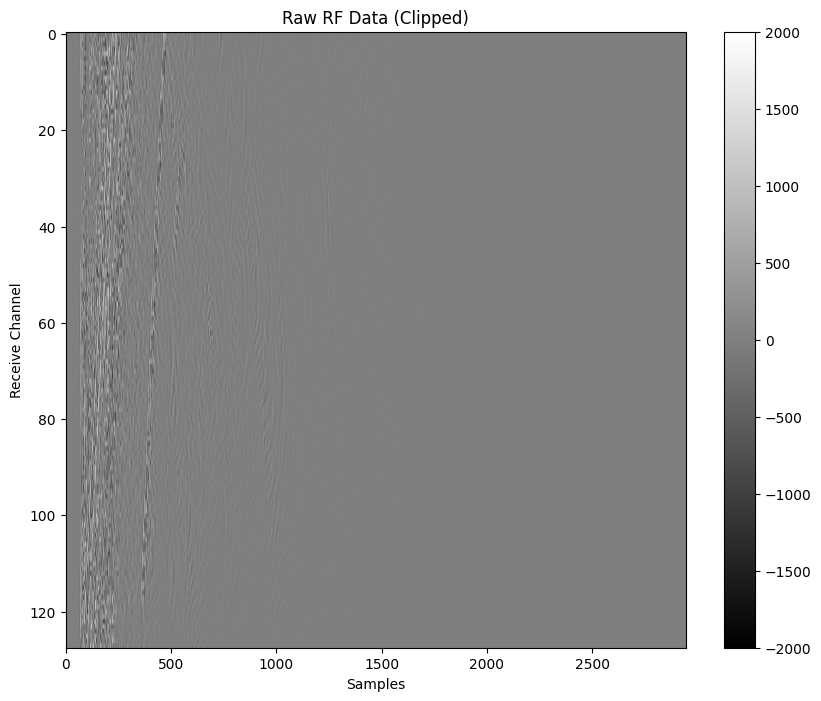

In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

plt.imshow(
    frame,
    cmap="gray",
    aspect="auto",
    vmin=-2000,
    vmax=2000
)

plt.xlabel("Samples")
plt.ylabel("Receive Channel")
plt.title("Raw RF Data (Clipped)")
plt.colorbar()
plt.show()

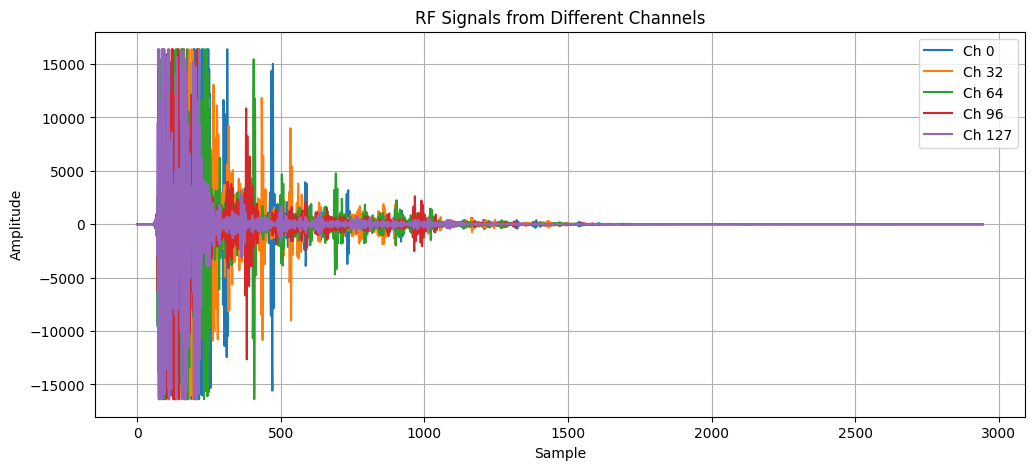

In [7]:
plt.figure(figsize=(12,5))

for ch in [0, 32, 64, 96, 127]:
    plt.plot(frame[ch], label=f"Ch {ch}")

plt.legend()
plt.title("RF Signals from Different Channels")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

In [9]:
from scipy.io import loadmat

header_file = r"D:\Real-Time Acceleration for Medical Image Processing\7986407\CIRS040GSE\CIRS040GSE\USHEADER_20220330104510.mat"

header = loadmat(header_file)

print(header.keys())

dict_keys(['__header__', '__version__', '__globals__', 'USHEADER'])


In [10]:
for k, v in header.items():
    if not k.startswith("__"):
        print(f"{k}: {type(v)}")

        try:
            print("Shape:", v.shape)
        except AttributeError:
            pass

        print()

USHEADER: <class 'numpy.ndarray'>
Shape: (1, 1)



In [11]:
usheader = header["USHEADER"]

print(type(usheader))
print(usheader.dtype)

<class 'numpy.ndarray'>
[('system', 'O'), ('transducer', 'O'), ('acquisitionDimension', 'O'), ('signalType', 'O'), ('c', 'O'), ('fc', 'O'), ('fbw', 'O'), ('fs', 'O'), ('pitch', 'O'), ('xmitAngles', 'O'), ('xmitDelay', 'O'), ('xmitFocus', 'O'), ('xmitApodFunction', 'O')]


In [ ]:
us = header["USHEADER"][0, 0]

for field in us.dtype.names:
    value = us[field]

    print("=" * 60)
    print(field)

    # MATLAB will store scalars as 1x1 arrays
    try:
        print(value.squeeze())
    except Exception:
        print(value)

system
Verasonics Vantage T256 R256
transducer
L12-5 50mm
acquisitionDimension
2D
signalType
RF_element
c
1540
fc
7813000
fbw
0.7679508511455267
fs
31250000
pitch
0.0001953
xmitAngles
[-16.         -15.56756757 -15.13513514 -14.7027027  -14.27027027
 -13.83783784 -13.40540541 -12.97297297 -12.54054054 -12.10810811
 -11.67567568 -11.24324324 -10.81081081 -10.37837838  -9.94594595
  -9.51351351  -9.08108108  -8.64864865  -8.21621622  -7.78378378
  -7.35135135  -6.91891892  -6.48648649  -6.05405405  -5.62162162
  -5.18918919  -4.75675676  -4.32432432  -3.89189189  -3.45945946
  -3.02702703  -2.59459459  -2.16216216  -1.72972973  -1.2972973
  -0.86486486  -0.43243243   0.           0.43243243   0.86486486
   1.2972973    1.72972973   2.16216216   2.59459459   3.02702703
   3.45945946   3.89189189   4.32432432   4.75675676   5.18918919
   5.62162162   6.05405405   6.48648649   6.91891892   7.35135135
   7.78378378   8.21621622   8.64864865   9.08108108   9.51351351
   9.94594595  10.3783783

In [14]:
import h5py
import numpy as np

file = r"D:\Real-Time Acceleration for Medical Image Processing\7986407\CIRS073_RUMC\CIRS073_RUMC\hyper_lesion2\USDATA_20210624113603277.mat"

with h5py.File(file, "r") as f:
    rf = np.array(f["USDATA"])

# Now rf is a NumPy array independent of the file
print(rf.shape)

for axis in range(rf.ndim):
    print(f"Axis {axis}: std = {rf.std(axis=axis).mean()}")

print("rf[0,0,:,:] shape:", rf[0,0,:,:].shape)
print("rf[:,0,0,:] shape:", rf[:,0,0,:].shape)
print("rf[:,:,0,0] shape:", rf[:,:,0,0].shape)

(75, 1, 128, 2944)
Axis 0: std = 861.5429353229292
Axis 1: std = 0.0
Axis 2: std = 752.2066035168049
Axis 3: std = 2134.9281669350685
rf[0,0,:,:] shape: (128, 2944)
rf[:,0,0,:] shape: (75, 2944)
rf[:,:,0,0] shape: (75, 1)
